# 04 - Clustering

Groups of applications with similar product profiles, using four methods: K-Means++, Agglomerative clustering
(Ward linkage), Gaussian Mixture Models and DBSCAN. The clusters are built without the label; the failure rate
is only used afterwards to describe them.

## Settings

In [1]:
K_RANGE = range(5, 51, 5)    # k values tried for K-Means and GMM
SELECT_SAMPLE = 50_000       # rows used to fit K-Means while choosing k
SAMPLE_SIZE = 15_000         # sample for Agglomerative, DBSCAN, silhouette and ARI
SVD_COMPONENTS = 30          # text components before PCA
PCA_VARIANCE = 0.80          # share of variance kept by PCA
DBSCAN_MIN_SAMPLES = 20
RANDOM_STATE = 42

In [2]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from features import feature_groups
from modeling import make_preprocessor, make_models

FIG, OUT = ROOT / "figures", ROOT / "outputs"
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

## 1. Representation

Each application is described by what it protects:
the 45 Nice class columns (binary) and the English goods description (TF-IDF, reduced with TruncatedSVD).
The Nice columns stay as 0/1 and the text components are L2-normalized, so for a typical application both parts
have a length of about 1 and neither dominates. The binary columns are **not** standardized: after standardizing,
a class that appears in 1% of applications would get a value of about 10 and would dominate every distance
(rare classes would become their own clusters). Then PCA keeps 80% of the variance
(reducing dimensions before clustering removes noise, as discussed in class).
Everything is fit on the training years only, so the same transformation can be applied to the test years
in the cluster-as-feature experiment.

In [3]:
feats = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
train = feats[feats["is_train"]].reset_index(drop=True)
test = feats[~feats["is_train"]].reset_index(drop=True)
nice_cols = [f"nice_{k}" for k in range(1, 46)]

# numbers and the words "class" / "included" appear in almost every description, so they are removed
stop_words = list(ENGLISH_STOP_WORDS | {"class", "classes", "included", "including"})
tfidf = TfidfVectorizer(stop_words=stop_words, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
                        min_df=5, max_features=20000, sublinear_tf=True)
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=RANDOM_STATE)
def represent(df, fit=False):
    tf = tfidf.fit_transform(df["goods_text"]) if fit else tfidf.transform(df["goods_text"])
    txt = svd.fit_transform(tf) if fit else svd.transform(tf)
    return np.hstack([df[nice_cols].to_numpy(float), normalize(txt)])

X_train_full = represent(train, fit=True)
pca = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE).fit(X_train_full)
Z_train = pca.transform(X_train_full)
Z_test = pca.transform(represent(test))
print(f"{X_train_full.shape[1]} columns -> {Z_train.shape[1]} PCA components "
      f"({pca.explained_variance_ratio_.sum():.0%} of the variance)")

75 columns -> 29 PCA components (80% of the variance)


## 2. Choosing k: elbow and silhouette (K-Means++), BIC (GMM)

K-Means is fit on a 50,000-row sample for each k, and the silhouette is computed on a 15,000-row sample.

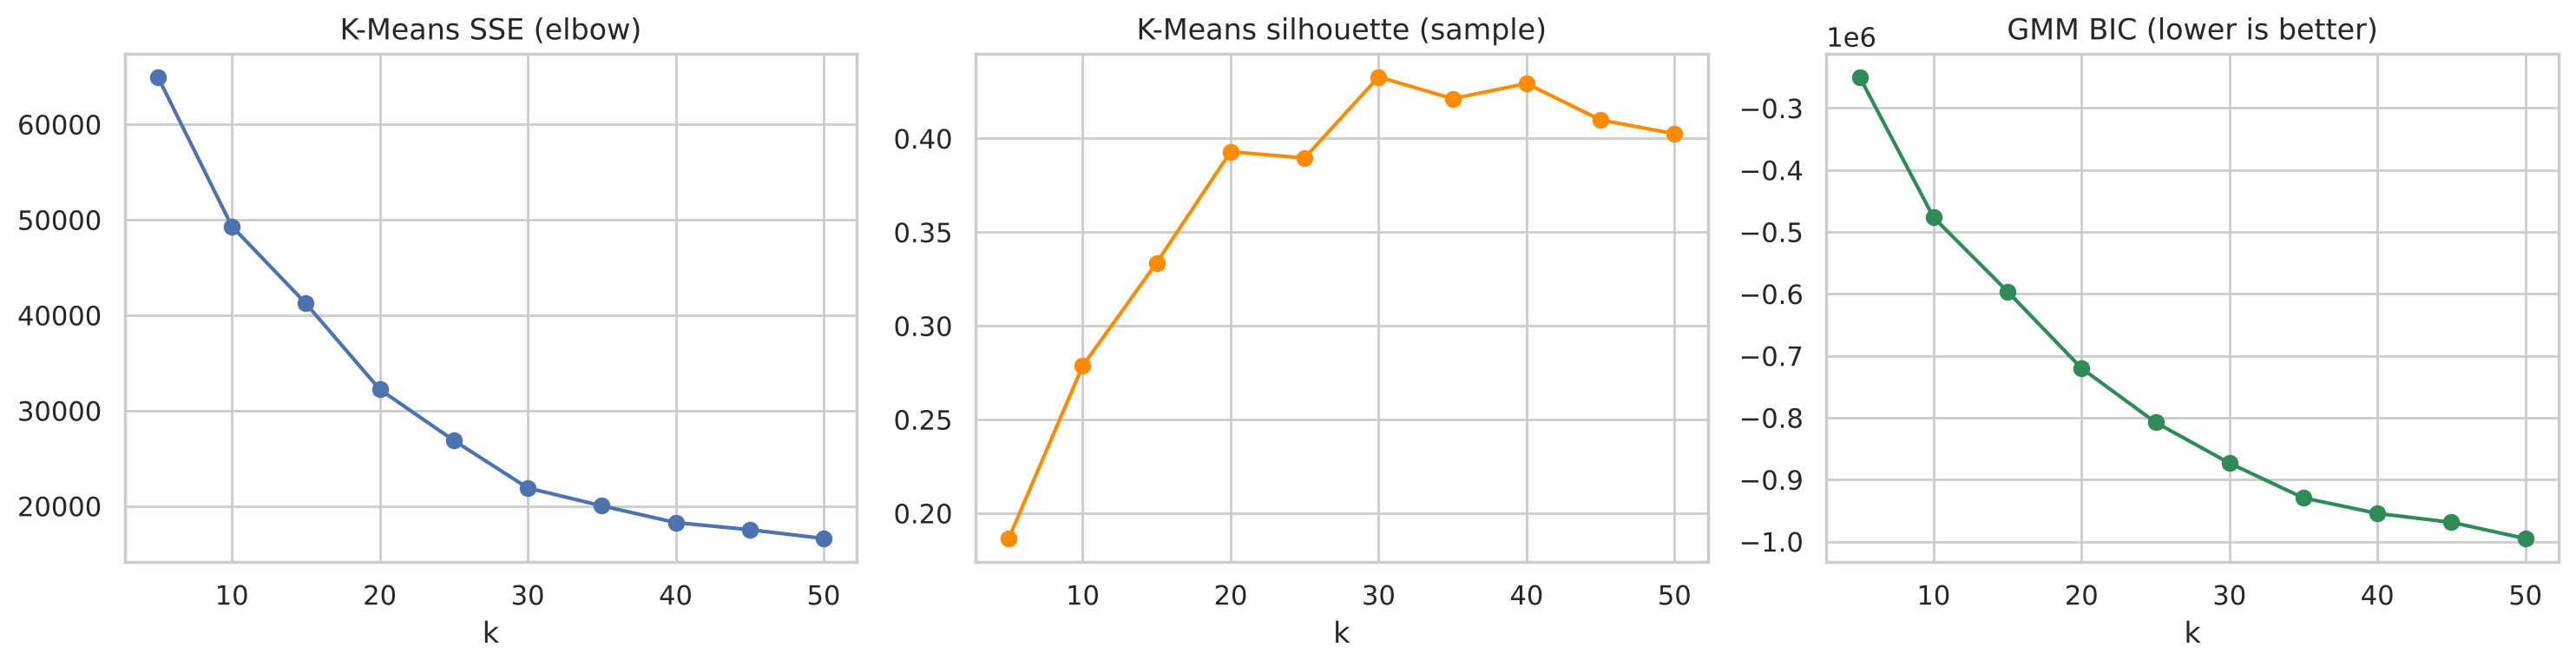

,SSE,silhouette,GMM BIC
k,,,
5,64963.667,0.187,-249657.412
10,49313.618,0.279,-476598.770
15,41233.426,0.334,-596228.177
20,32220.353,0.393,-720180.151
25,26878.459,0.390,-807569.537
30,21902.558,0.433,-873450.531
35,20033.113,0.421,-929535.925
40,18274.367,0.429,-954577.484
45,17528.444,0.410,-969017.280


In [4]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(Z_train), SAMPLE_SIZE, replace=False)
Z_sample = Z_train[sample_idx]
Z_select = Z_train[rng.choice(len(Z_train), SELECT_SAMPLE, replace=False)]

rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=3, random_state=RANDOM_STATE).fit(Z_select)
    gmm = GaussianMixture(n_components=k, covariance_type="diag", random_state=RANDOM_STATE).fit(Z_sample)
    rows.append({"k": k, "SSE": km.inertia_,
                 "silhouette": silhouette_score(Z_sample, km.predict(Z_sample)),
                 "GMM BIC": gmm.bic(Z_sample)})
k_table = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
k_table["SSE"].plot(ax=axes[0], marker="o", title="K-Means SSE (elbow)")
k_table["silhouette"].plot(ax=axes[1], marker="o", color="darkorange", title="K-Means silhouette (sample)")
k_table["GMM BIC"].plot(ax=axes[2], marker="o", color="seagreen", title="GMM BIC (lower is better)")
plt.tight_layout()
plt.savefig(FIG / "choosing_k.png", dpi=120)
plt.show()
k_table.round(3)

In [5]:
K = int(k_table["silhouette"].idxmax())
K_GMM = K   # same k for all methods, so the comparison is fair
print("k chosen by silhouette:", K, "(used for K-Means, Agglomerative and GMM)")
print("k with the lowest GMM BIC in the range:", int(k_table["GMM BIC"].idxmin()))

k chosen by silhouette: 30 (used for K-Means, Agglomerative and GMM)
k with the lowest GMM BIC in the range: 50


## 3. Fit the four methods

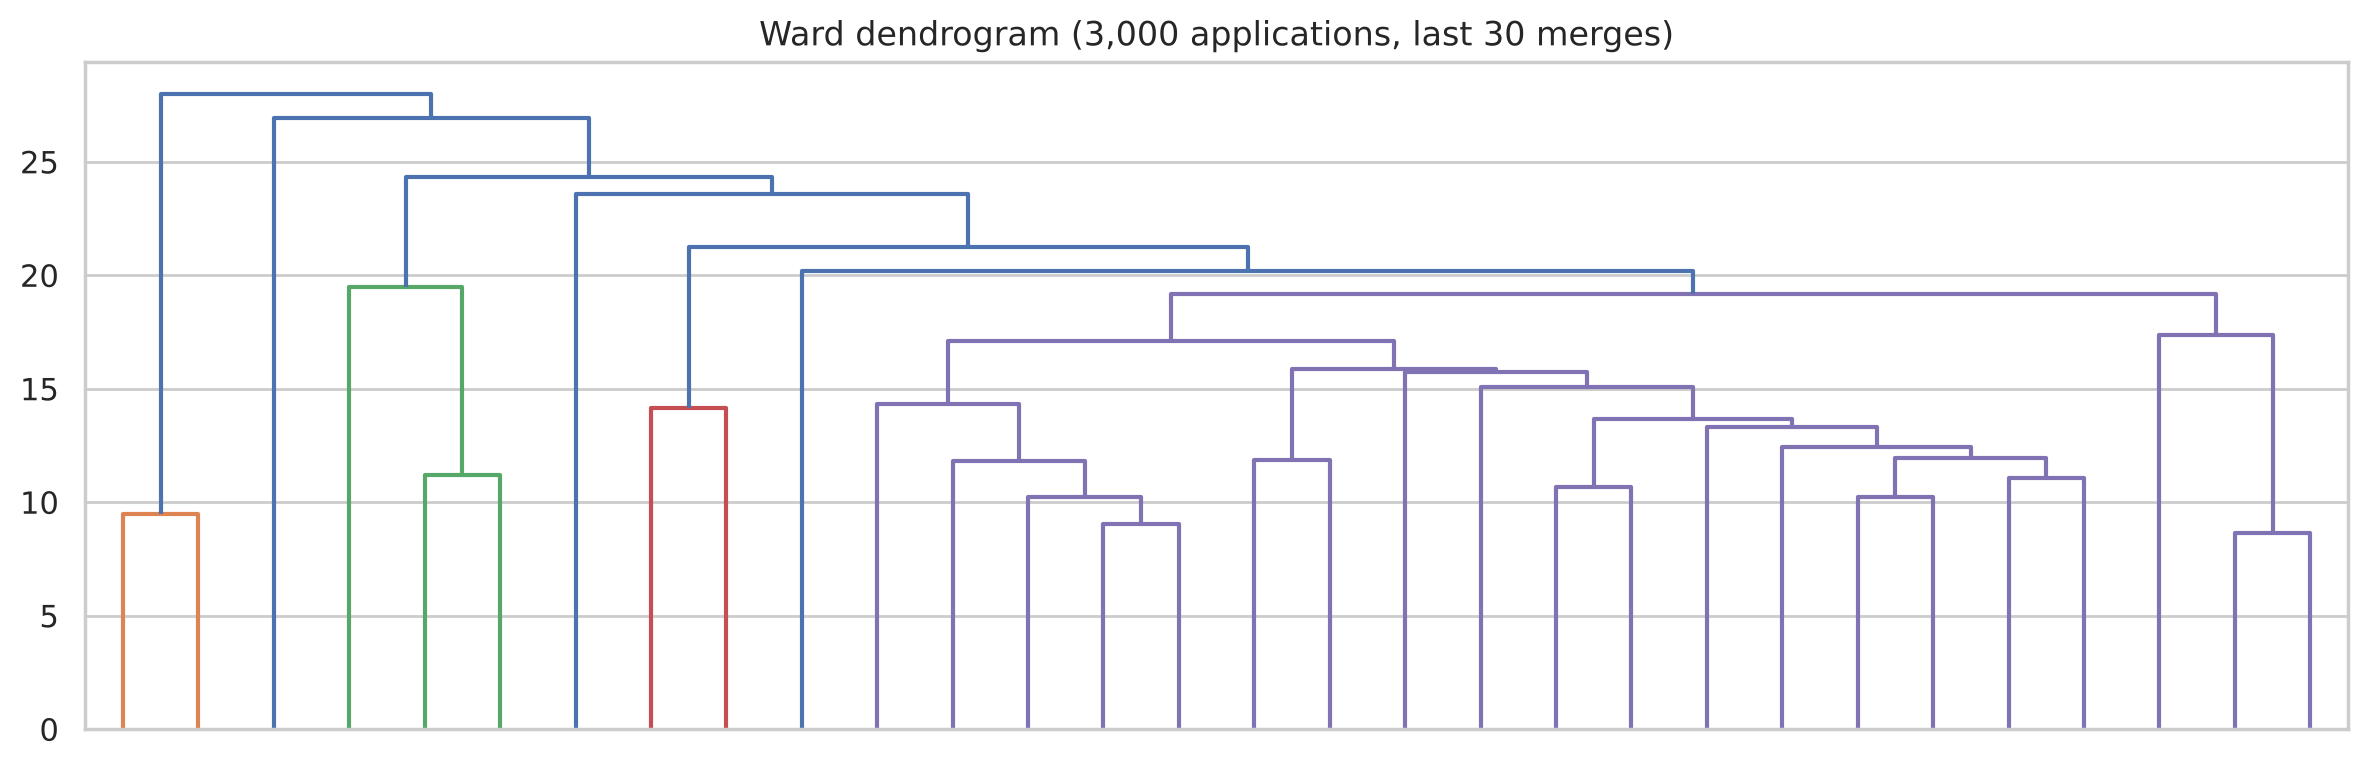

In [6]:
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(Z_train)
gmm = GaussianMixture(n_components=K_GMM, covariance_type="diag", random_state=RANDOM_STATE).fit(Z_sample)

# Agglomerative needs the full distance structure, so it runs on the sample
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z_sample)

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(linkage(Z_sample[:3000], method="ward"), truncate_mode="lastp", p=30, ax=ax, no_labels=True)
ax.set_title("Ward dendrogram (3,000 applications, last 30 merges)")
plt.tight_layout()
plt.savefig(FIG / "dendrogram.png", dpi=120)
plt.show()

**DBSCAN parameters.** `min_samples` is fixed and `eps` is taken from the k-distance plot (the distance to the
`min_samples`-th neighbour, sorted). The knee is found automatically as the point farthest from the straight line
between the two ends of the curve. A small table then shows how sensitive the result is to `eps`.

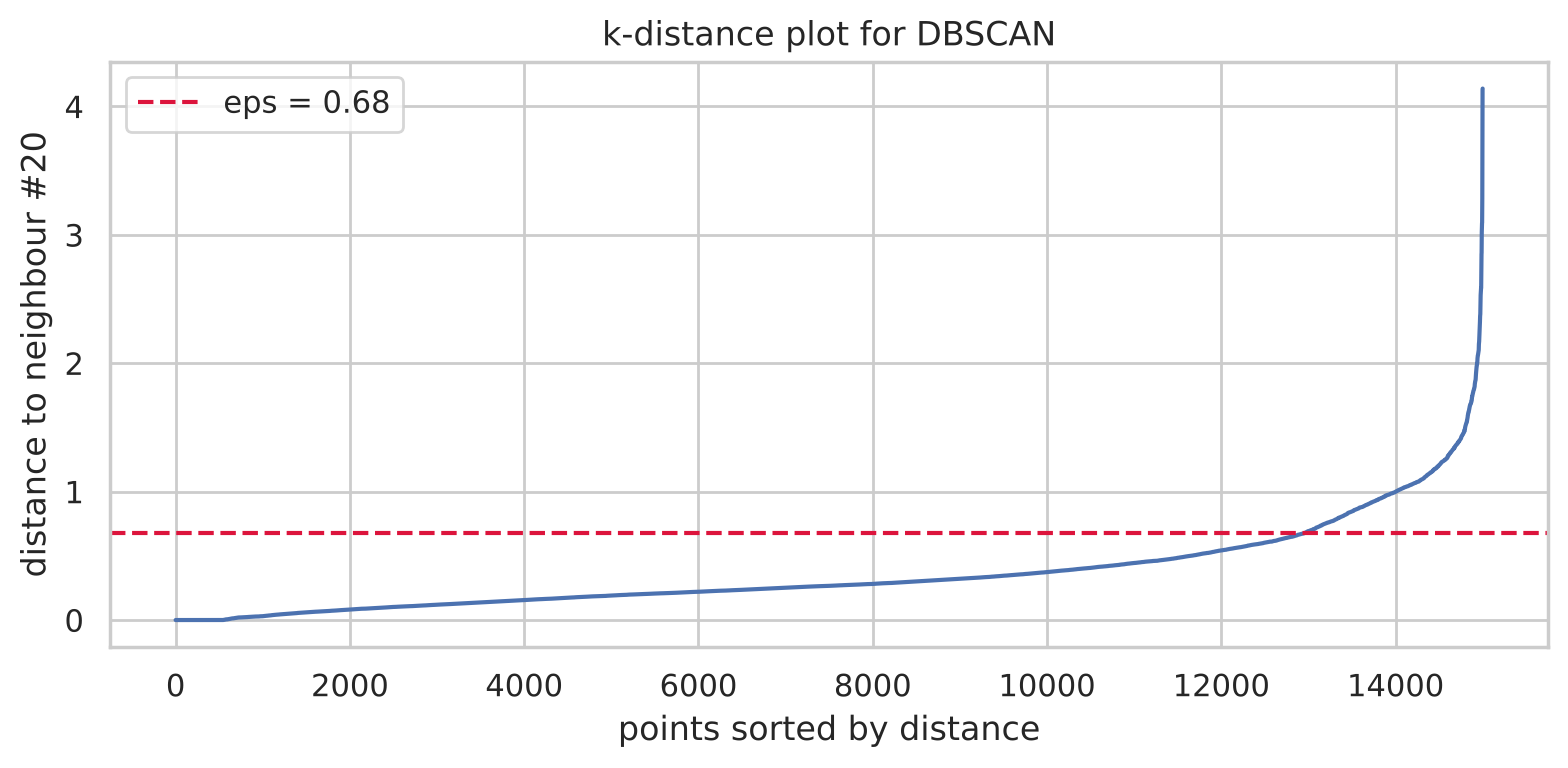

,eps,clusters,noise %,largest cluster %
0,0.406,39,22.0,11.1
1,0.541,29,14.1,33.2
2,0.677,13,10.4,68.9
3,0.812,3,7.0,94.1
4,1.015,1,3.0,100.0


DBSCAN clusters: 13 | noise points: 10.4%


In [7]:
nn = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(Z_sample)
kdist = np.sort(nn.kneighbors(Z_sample)[0][:, -1])
# knee: point of the normalized curve farthest from the line joining its first and last points
x = np.linspace(0, 1, len(kdist))
y = (kdist - kdist.min()) / (kdist.max() - kdist.min())
knee = int(np.argmax(np.abs(y - x)))
EPS = float(kdist[knee])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kdist)
ax.axhline(EPS, color="crimson", ls="--", label=f"eps = {EPS:.2f}")
ax.set(xlabel="points sorted by distance", ylabel=f"distance to neighbour #{DBSCAN_MIN_SAMPLES}",
       title="k-distance plot for DBSCAN")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "dbscan_kdistance.png", dpi=120)
plt.show()

sens = []
for factor in [0.6, 0.8, 1.0, 1.2, 1.5]:
    lab = DBSCAN(eps=EPS * factor, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(Z_sample)
    sens.append({"eps": round(EPS * factor, 3), "clusters": len(set(lab)) - (-1 in lab),
                 "noise %": round((lab == -1).mean() * 100, 1),
                 "largest cluster %": round(pd.Series(lab[lab != -1]).value_counts(normalize=True).iloc[0] * 100, 1)})
display(pd.DataFrame(sens))

dbscan = DBSCAN(eps=EPS, min_samples=DBSCAN_MIN_SAMPLES).fit(Z_sample)
db_labels = dbscan.labels_
print("DBSCAN clusters:", len(set(db_labels)) - (-1 in db_labels), "| noise points:", f"{(db_labels == -1).mean():.1%}")

## 4. Comparing the methods

All four are compared on the same sample. Silhouette for DBSCAN is computed without its noise points.
ARI measures how much two methods agree (1 = identical partitions, 0 = chance level).

,clusters,silhouette,largest cluster share
method,,,
K-Means++,30,0.452,0.100
Agglomerative (Ward),30,0.427,0.101
GMM,30,0.325,0.111
DBSCAN,13,0.143,0.689


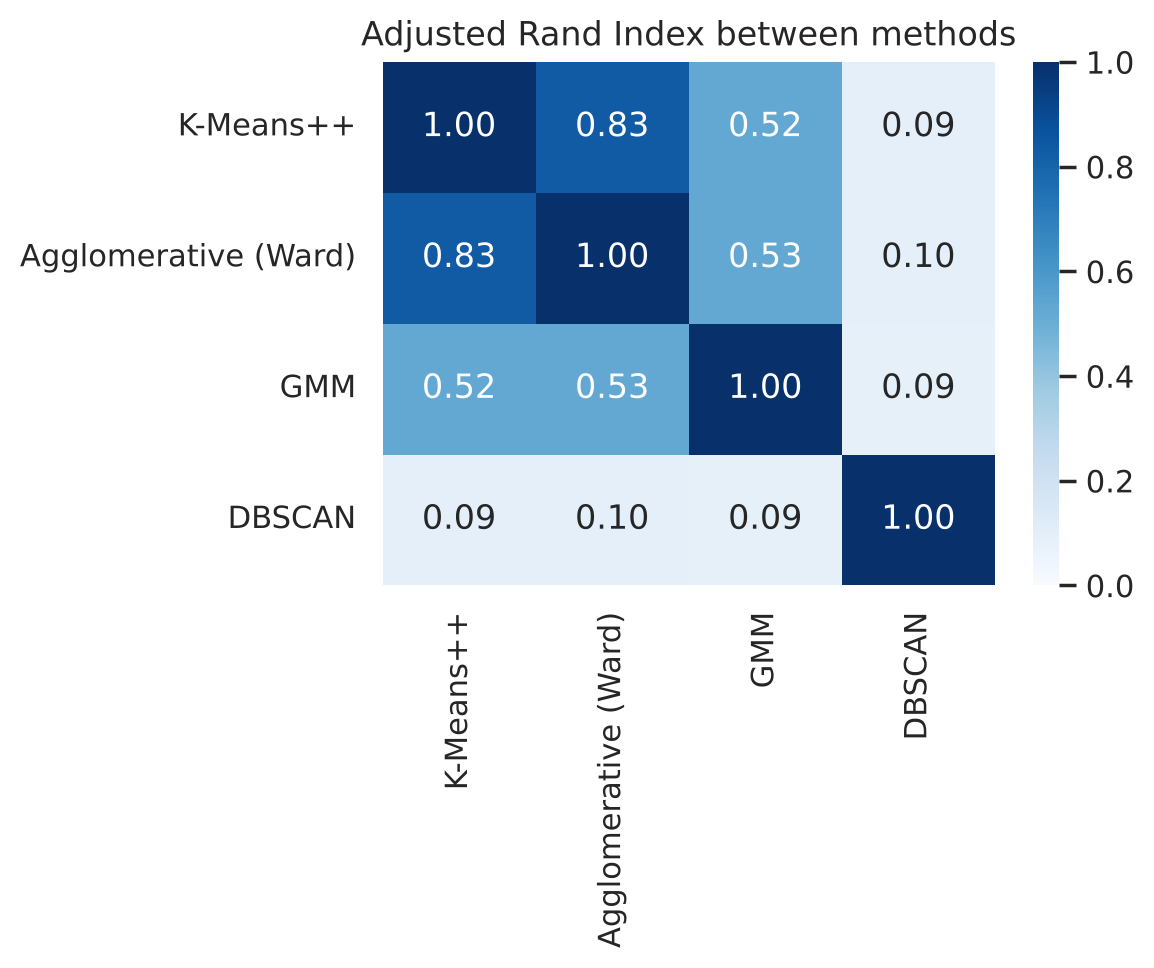

In [8]:
labels = {
    "K-Means++": kmeans.predict(Z_sample),
    "Agglomerative (Ward)": agg.labels_,
    "GMM": gmm.predict(Z_sample),
    "DBSCAN": db_labels,
}
comparison = []
for name, lab in labels.items():
    mask = lab != -1 if name == "DBSCAN" else np.ones(len(lab), bool)
    comparison.append({"method": name, "clusters": len(set(lab[mask])),
                       "silhouette": silhouette_score(Z_sample[mask], lab[mask]),
                       "largest cluster share": pd.Series(lab[mask]).value_counts(normalize=True).iloc[0]})
display(pd.DataFrame(comparison).set_index("method").round(3))

ari = pd.DataFrame({a: {b: adjusted_rand_score(labels[a], labels[b]) for b in labels} for a in labels})
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Adjusted Rand Index between methods")
plt.tight_layout()
plt.savefig(FIG / "ari_between_methods.png", dpi=120)
plt.show()

**Choosing k.** There is no clear elbow. The silhouette rises until about 30 clusters (0.43) and then stays flat,
so we use k = 30 for K-Means, Agglomerative and GMM. The GMM BIC keeps going down up to 50, the edge of the range,
which is common for BIC on large samples; we keep the same k for all three so the comparison is fair.
Before we stopped standardizing the binary Nice columns, the silhouette peaked at 45, the number of Nice classes,
because the rare classes dominated the distances.

**DBSCAN.** The knee of the k-distance curve gives eps = 0.68. The sensitivity table shows how fragile DBSCAN is here:
a bit lower and the data breaks into many small groups with a lot of noise, a bit higher and almost everything is one cluster.

**Comparison.** K-Means++ and Agglomerative (Ward) give almost the same partition (ARI 0.83) and the best silhouette
(0.45 and 0.43). GMM agrees with them only partly (ARI about 0.52), and its membership probabilities are almost always
close to 1, so the soft assignment adds little. DBSCAN agrees with none of them (ARI about 0.1) and keeps 69% of the
points in one cluster. Density doesn't separate these groups well, but its noise points are useful (section 6).

## 5. What the K-Means clusters contain, and how often they fail

In [9]:
train["cluster"] = kmeans.labels_
base = train["failed"].mean()
terms = np.array(tfidf.get_feature_names_out())

def top_terms(c, n=6):
    # mean TF-IDF of the cluster's goods descriptions
    docs = tfidf.transform(train.loc[train["cluster"] == c, "goods_text"].sample(
        min(3000, (train["cluster"] == c).sum()), random_state=RANDOM_STATE))
    return ", ".join(terms[np.asarray(docs.mean(axis=0)).ravel().argsort()[::-1][:n]])

profile = []
for c, g in train.groupby("cluster"):
    nice_share = g[nice_cols].mean().sort_values(ascending=False)
    profile.append({"cluster": c, "size": len(g), "failure_rate": g["failed"].mean(),
                    "lift": g["failed"].mean() / base,
                    "main Nice classes": ", ".join(f"{n.split('_')[1]} ({v:.0%})" for n, v in nice_share.head(3).items()),
                    "top goods terms": top_terms(c)})
profile = pd.DataFrame(profile).set_index("cluster").sort_values("failure_rate", ascending=False)
profile.round(3)

,size,failure_rate,lift,main Nice classes,top goods terms
cluster,,,,,
16,3980,0.234,1.534,"38 (100%), 9 (7%), 41 (5%)","services, telecommunication, telecommunication..."
7,7138,0.234,1.529,"42 (100%), 35 (4%), 44 (2%)","services, computer, design, software, developm..."
26,4005,0.210,1.376,"43 (93%), 31 (7%), 35 (3%)","food, services, drink, providing, restaurant, ..."
12,10100,0.201,1.313,"35 (100%), 42 (3%), 41 (3%)","business, advertising, services, management, r..."
5,8682,0.191,1.252,"41 (100%), 9 (6%), 35 (5%)","entertainment, services, education, training, ..."
22,5345,0.187,1.221,"29 (87%), 30 (25%), 31 (18%)","milk, meat, vegetables, products, fruits, fish"
6,9460,0.185,1.208,"25 (100%), 35 (3%), 24 (2%)","clothing, footwear, headgear, shirts, shoes, hats"
9,6809,0.179,1.173,"30 (100%), 29 (3%), 43 (3%)","confectionery, coffee, chocolate, tea, pastry,..."
17,3643,0.177,1.160,"32 (100%), 33 (7%), 30 (4%)","drinks, fruit, beverages, alcoholic, juices, non"


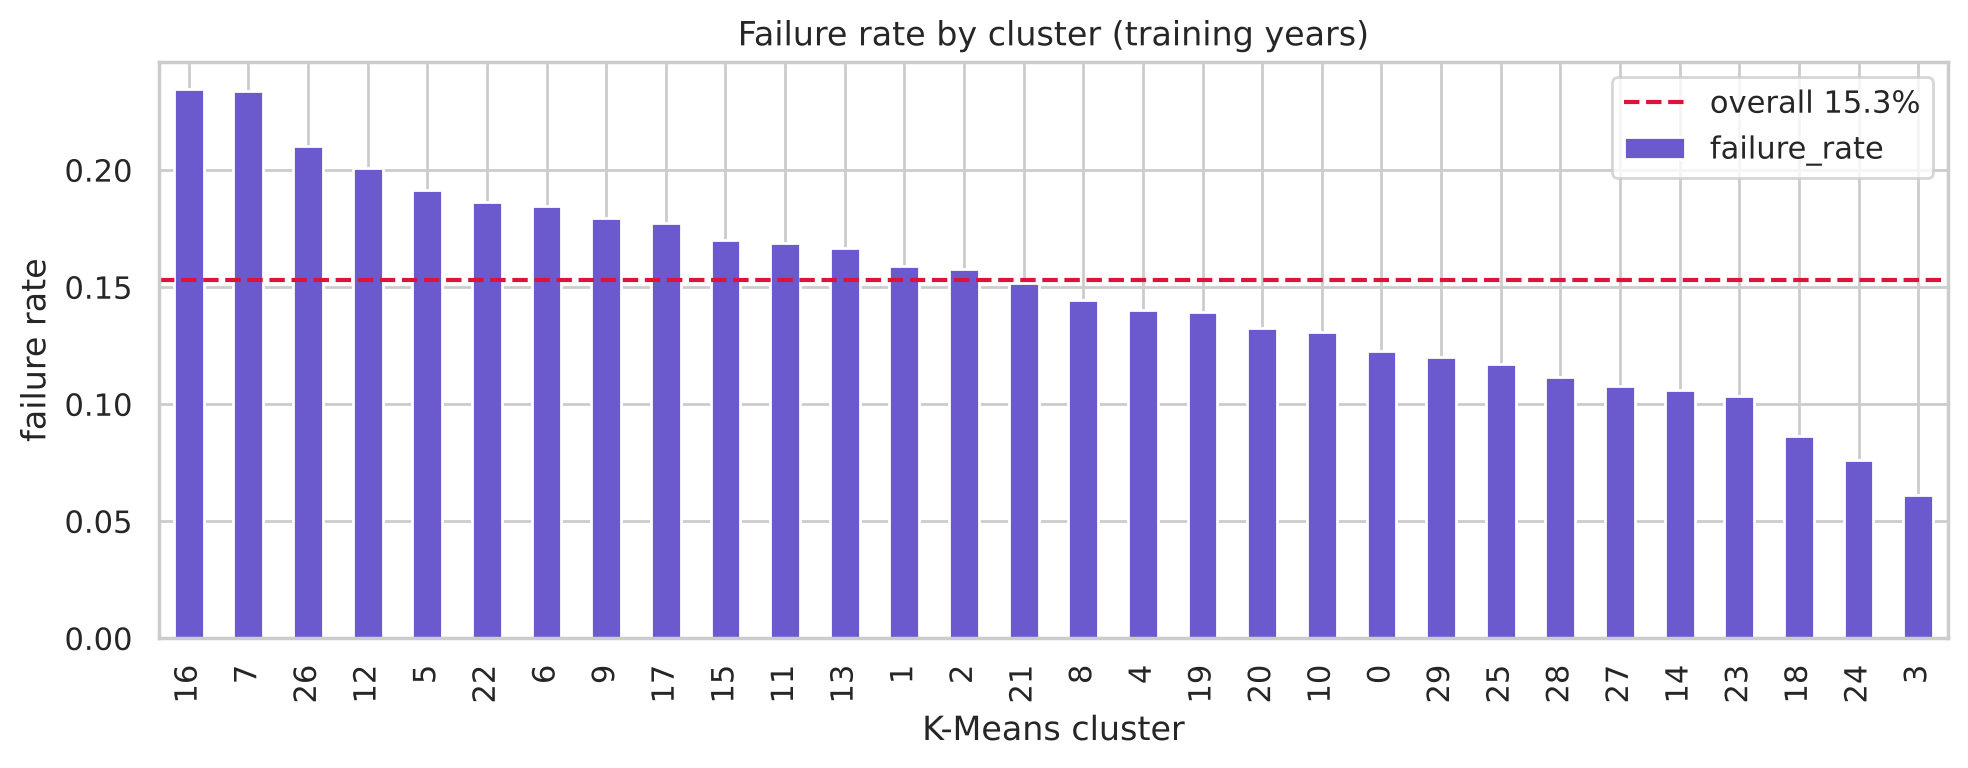

GMM: median membership probability 1.00, 0.5% of points have no cluster above 0.6


In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
profile["failure_rate"].plot.bar(ax=ax, color="slateblue")
ax.axhline(base, color="crimson", ls="--", label=f"overall {base:.1%}")
ax.set(xlabel="K-Means cluster", ylabel="failure rate", title="Failure rate by cluster (training years)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "failure_by_cluster.png", dpi=120)
plt.show()

gmm_conf = gmm.predict_proba(Z_sample).max(axis=1)
print(f"GMM: median membership probability {np.median(gmm_conf):.2f}, "
      f"{(gmm_conf < 0.6).mean():.1%} of points have no cluster above 0.6")

**Clusters and failure.** Most clusters are built around one Nice class, but some combine classes in a meaningful way.
Service clusters fail the most: telecommunications (class 38) and computer services (42) at 23%, restaurants (43) at 21%
and advertising and business (35) at 20%. Chemicals and pharmaceuticals for treating diseases fail the least (6-9%).

Two findings that the class number alone doesn't show:
1. Computer services filed alone (class 42) fail at 23%, while software filed in both class 9 and class 42 fails at 12%.
2. Class 5 splits by the goods text: pharmaceuticals for treating diseases fail at 6%, food supplements and other medical
   preparations at 14%.
Broad applications that cover several consumer classes together (for example clothing, electronics and leather goods)
fail the least of all, at 8%.

## 6. Anomalies: DBSCAN noise points

Applications DBSCAN couldn't place in any dense area. Do they fail more often?

In [11]:
sample_failed = train.loc[sample_idx, "failed"].to_numpy()
anomaly = pd.DataFrame({"noise": db_labels == -1, "failed": sample_failed,
                        "n_classes": train.loc[sample_idx, "n_classes"].to_numpy()})
anomaly.groupby("noise").agg(n=("failed", "size"), failure_rate=("failed", "mean"),
                             mean_classes=("n_classes", "mean")).round(3)

,n,failure_rate,mean_classes
noise,,,
False,13444,0.158,1.108
True,1556,0.125,4.126


**Anomalies.** The 10% of applications DBSCAN marks as noise cover about 4 Nice classes on average, compared with about 1
for the rest. These broad applications fail less often (12.5% vs 15.8%), which matches what we saw for the number of classes in notebook 01.

## 7. Does the cluster help the classifier?

LightGBM with the tuned parameters from notebook 03, with and without the K-Means cluster as an extra
categorical feature. K-Means was fit on training years only and assigns test applications by nearest centroid.

In [12]:
best_params = json.loads((OUT / "best_params.json").read_text())["LightGBM"]
numeric, categorical, text = feature_groups(feats.columns)
train["kmeans_cluster"] = kmeans.labels_.astype(str)
test["kmeans_cluster"] = kmeans.predict(Z_test).astype(str)
X_cols = numeric + categorical + [text, "kmeans_cluster"]

rows = []
for with_cluster in [False, True]:
    cats = categorical + (["kmeans_cluster"] if with_cluster else [])
    pipe = Pipeline([("pre", make_preprocessor(numeric, cats, text)),
                     ("model", clone(make_models()["LightGBM"]))]).set_params(**best_params)
    pipe.fit(train[X_cols], train["failed"])
    p = pipe.predict_proba(test[X_cols])[:, 1]
    rows.append({"features": "with cluster" if with_cluster else "without cluster",
                 "test ROC-AUC": roc_auc_score(test["failed"], p),
                 "test PR-AUC": average_precision_score(test["failed"], p)})
pd.DataFrame(rows).set_index("features").round(4)

,test ROC-AUC,test PR-AUC
features,,
without cluster,0.7230,0.343
with cluster,0.7236,0.346


**Cluster as a feature.** Adding the cluster barely changes the test score (PR-AUC 0.343 without it, 0.346 with it).
That makes sense: the model already gets the Nice classes and the goods text that the clusters are built from.

In [13]:
profile.to_csv(OUT / "kmeans_cluster_profile.csv")
print("saved")

saved
